In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

In [2]:
df = pd.read_csv('../Data/Iris.csv')

In [3]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df = df.iloc[:,1:]

In [5]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
from sklearn.preprocessing import LabelEncoder

In [7]:
encoder = LabelEncoder()

In [8]:
df['Species'] = encoder.fit_transform(df['Species'])

In [9]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [10]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [11]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

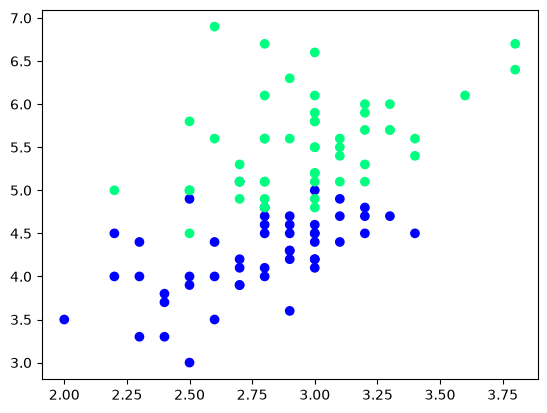

In [13]:
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')

In [14]:
df_train = df.iloc[:60,:].sample(10)
df_train

,SepalWidthCm,PetalLengthCm,Species
91,3.0,4.6,1
56,3.3,4.7,1
50,3.2,4.7,1
62,2.2,4.0,1
90,2.6,4.4,1
94,2.7,4.2,1
66,3.0,4.5,1
52,3.1,4.9,1
54,2.8,4.6,1
64,2.9,3.6,1


In [15]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [16]:
df_train

,SepalWidthCm,PetalLengthCm,Species
101,2.7,5.1,2
143,3.2,5.9,2
104,3.0,5.8,2
66,3.0,4.5,1
95,3.0,4.2,1
92,2.6,4.0,1
89,2.5,4.0,1
59,2.7,3.9,1
99,2.8,4.1,1
65,3.1,4.4,1


In [17]:
df_val

,SepalWidthCm,PetalLengthCm,Species
100,3.3,6.0,2
136,3.4,5.6,2
115,3.2,5.3,2
85,3.4,4.5,1
127,3.0,4.9,2


In [18]:
df_test

,SepalWidthCm,PetalLengthCm,Species
121,2.8,4.9,2
119,2.2,5.0,2
107,2.9,6.3,2
64,2.9,3.6,1
113,2.5,5.0,2


In [19]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [20]:
y_test

array([2, 2, 2, 1, 2])

In [25]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

# Case 1 - Bagging

In [26]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,SepalWidthCm,PetalLengthCm,Species
101,2.7,5.1,2
92,2.6,4.0,1
65,3.1,4.4,1
89,2.5,4.0,1
59,2.7,3.9,1
95,3.0,4.2,1
143,3.2,5.9,2
99,2.8,4.1,1


In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [28]:
dt_bag1 = DecisionTreeClassifier()

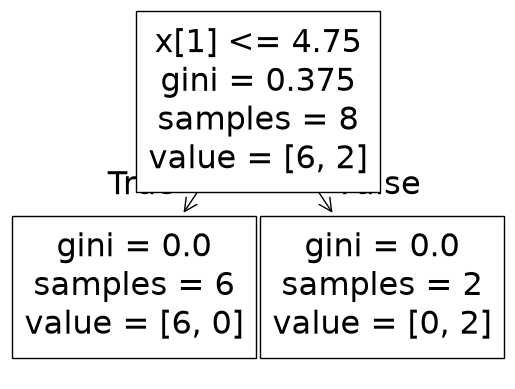

C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


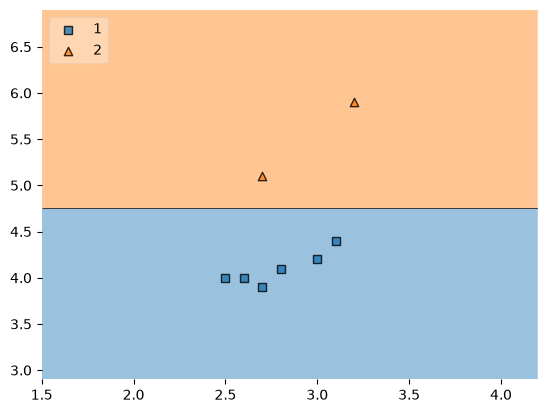

In [29]:
evaluate(dt_bag1,X,y)

In [30]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
104,3.0,5.8,2
143,3.2,5.9,2
95,3.0,4.2,1
92,2.6,4.0,1
101,2.7,5.1,2
104,3.0,5.8,2
89,2.5,4.0,1
89,2.5,4.0,1


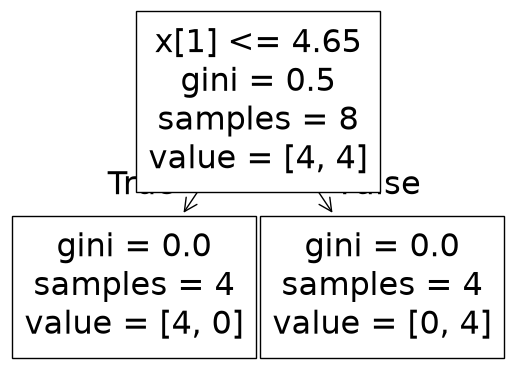

C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


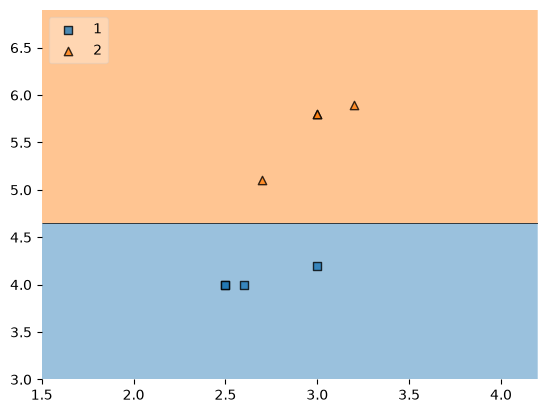

In [31]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [32]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
101,2.7,5.1,2
143,3.2,5.9,2
89,2.5,4.0,1
101,2.7,5.1,2
95,3.0,4.2,1
101,2.7,5.1,2
92,2.6,4.0,1
95,3.0,4.2,1


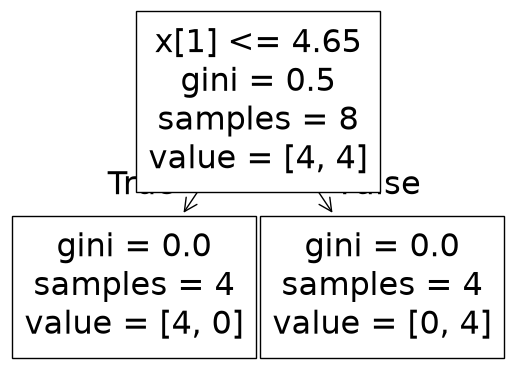

C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


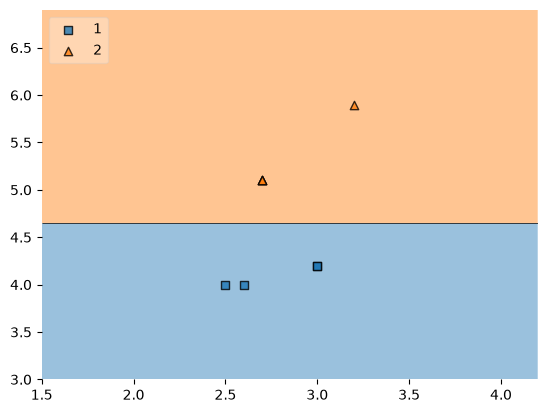

In [33]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

## Predict

In [34]:
df_test

,SepalWidthCm,PetalLengthCm,Species
121,2.8,4.9,2
119,2.2,5.0,2
107,2.9,6.3,2
64,2.9,3.6,1
113,2.5,5.0,2


In [35]:
print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [2]
Predictor 3 [2]


C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# Pasting

In [36]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
101,2.7,5.1,2
143,3.2,5.9,2
104,3.0,5.8,2
66,3.0,4.5,1
95,3.0,4.2,1
92,2.6,4.0,1
89,2.5,4.0,1
59,2.7,3.9,1
99,2.8,4.1,1
65,3.1,4.4,1


In [37]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
59,2.7,3.9,1
92,2.6,4.0,1
101,2.7,5.1,2
143,3.2,5.9,2
65,3.1,4.4,1
89,2.5,4.0,1
104,3.0,5.8,2
66,3.0,4.5,1


# Random Subspaces

In [39]:
df1 = pd.read_csv('../Data/Iris.csv')
df1 = df1.sample(10)

In [40]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
72,73,6.3,2.5,4.9,1.5,Iris-versicolor
56,57,6.3,3.3,4.7,1.6,Iris-versicolor
59,60,5.2,2.7,3.9,1.4,Iris-versicolor
114,115,5.8,2.8,5.1,2.4,Iris-virginica
103,104,6.3,2.9,5.6,1.8,Iris-virginica
142,143,5.8,2.7,5.1,1.9,Iris-virginica
27,28,5.2,3.5,1.5,0.2,Iris-setosa
81,82,5.5,2.4,3.7,1.0,Iris-versicolor
111,112,6.4,2.7,5.3,1.9,Iris-virginica
40,41,5.0,3.5,1.3,0.3,Iris-setosa


In [41]:
df1.sample(2,replace=True,axis=1)

,PetalLengthCm,SepalWidthCm
72,4.9,2.5
56,4.7,3.3
59,3.9,2.7
114,5.1,2.8
103,5.6,2.9
142,5.1,2.7
27,1.5,3.5
81,3.7,2.4
111,5.3,2.7
40,1.3,3.5


# Random Patches

In [42]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
72,73,6.3,2.5,4.9,1.5,Iris-versicolor
56,57,6.3,3.3,4.7,1.6,Iris-versicolor
59,60,5.2,2.7,3.9,1.4,Iris-versicolor
114,115,5.8,2.8,5.1,2.4,Iris-virginica
103,104,6.3,2.9,5.6,1.8,Iris-virginica
142,143,5.8,2.7,5.1,1.9,Iris-virginica
27,28,5.2,3.5,1.5,0.2,Iris-setosa
81,82,5.5,2.4,3.7,1.0,Iris-versicolor
111,112,6.4,2.7,5.3,1.9,Iris-virginica
40,41,5.0,3.5,1.3,0.3,Iris-setosa


In [43]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,SepalWidthCm,Species
56,3.3,Iris-versicolor
142,2.7,Iris-virginica
142,2.7,Iris-virginica
40,3.5,Iris-setosa
59,2.7,Iris-versicolor
81,2.4,Iris-versicolor
81,2.4,Iris-versicolor
103,2.9,Iris-virginica
